In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import numpy as np

npy_path = '/content/drive/MyDrive/wood data/wood/Thz/Copy of Diverse_THz.npy'
data = np.load(npy_path, mmap_mode='r')
print("Data shape:", data.shape)

Data shape: (78, 140, 73, 512)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_species_signal(data, df, species_name):

    species_df = df[df["Species"].str.lower() == species_name.lower()]
    if species_df.empty:

        return

    sample_idx = species_df.index[0]

    sample_data = data[sample_idx]


    std_map = sample_data.std(axis=0)


    flat = std_map.flatten()
    sorted_idx = flat.argsort()
    H, W = std_map.shape

    normal_coord = divmod(sorted_idx[0], W)
    defect_coord = divmod(sorted_idx[-1], W)


    signal_normal = sample_data[:, normal_coord[0], normal_coord[1]]
    signal_defect = sample_data[:, defect_coord[0], defect_coord[1]]


    plt.figure(figsize=(10, 4))

    plt.plot(np.abs(signal_normal), label=f'Normal Pixel ({normal_coord})', color='green')
    plt.plot(np.abs(signal_defect), label=f'Defect Pixel ({defect_coord})', color='red')
    plt.title(f"{species_name} — Temporal Signal (Sample Index {sample_idx})")
    plt.xlabel('Time')
    plt.ylabel('Magnitude of Signal')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()



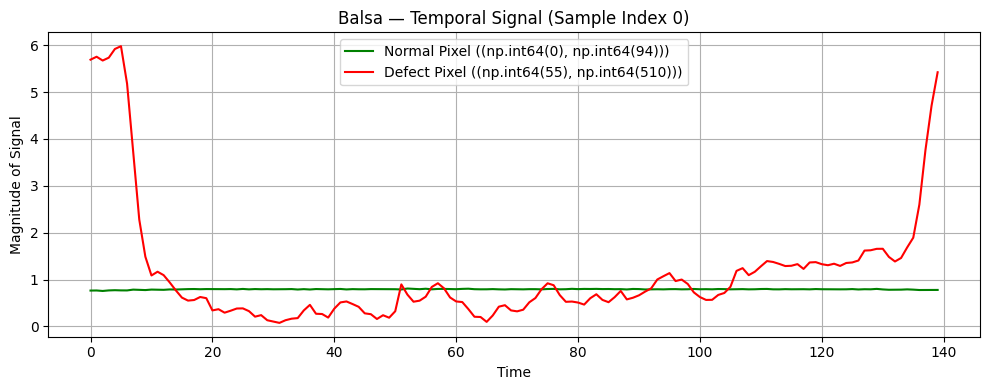

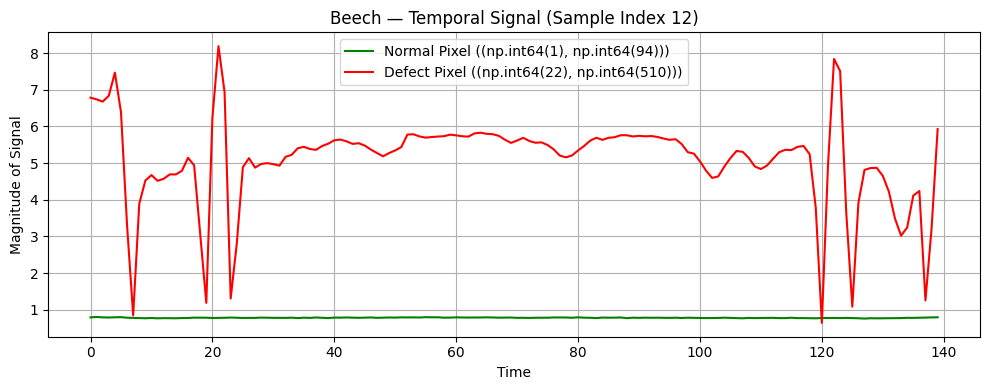

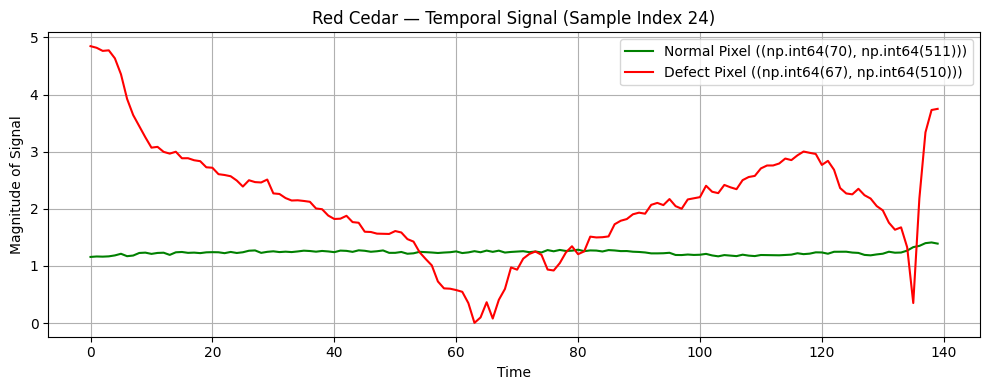

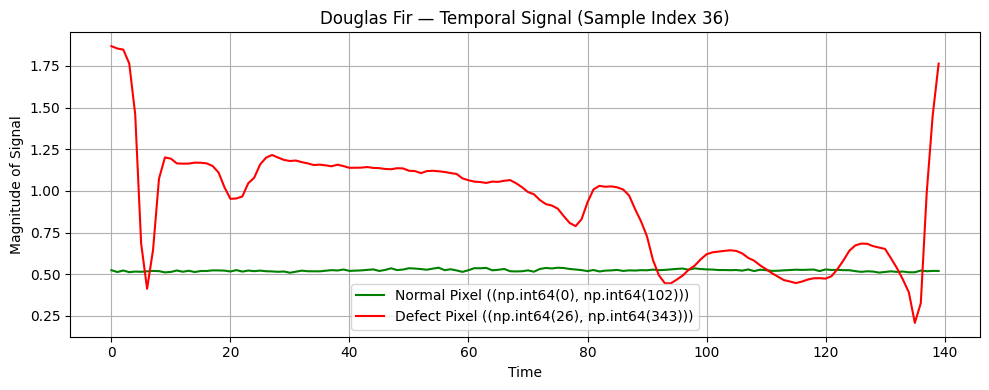

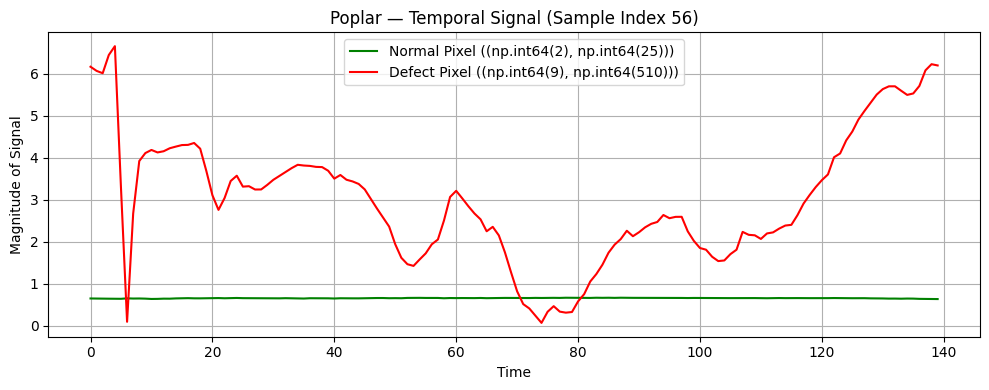

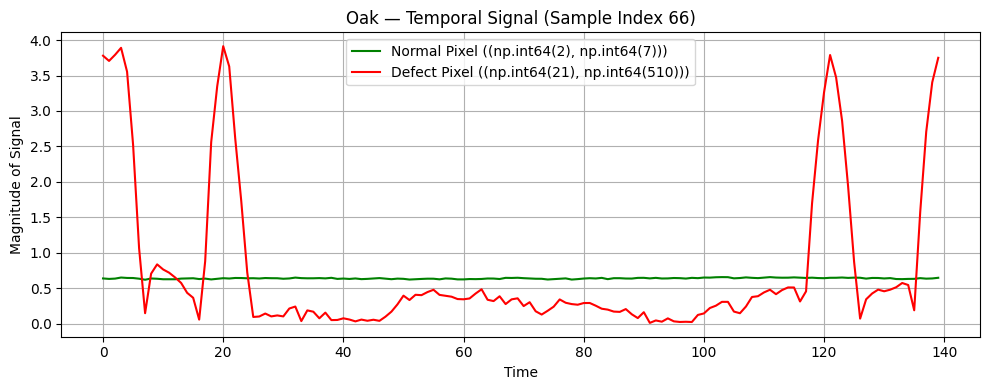

In [ ]:
for species in ["Balsa", "Beech", "Red Cedar", "Douglas Fir", "Poplar", "Oak"]:
    plot_species_signal(data, df, species)



[BALSA] Selected Low-STD Pixel Coordinates:
1. Pixel at (row=123, col=53) with STD = 0.6793
2. Pixel at (row=22, col=21) with STD = 0.6830
3. Pixel at (row=123, col=20) with STD = 0.6892


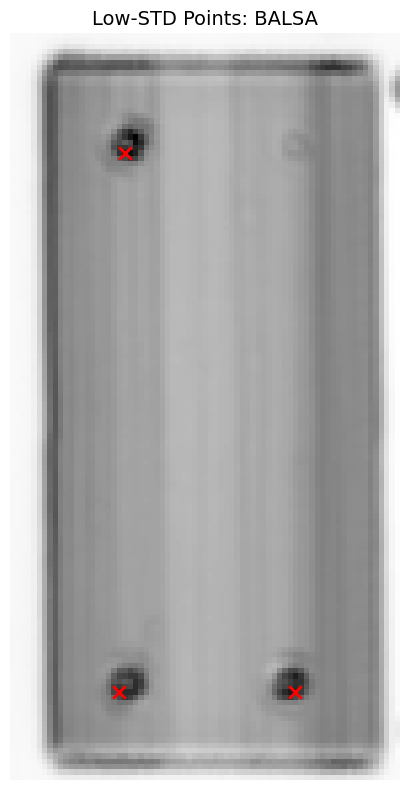


[BEECH] Selected Low-STD Pixel Coordinates:
1. Pixel at (row=124, col=53) with STD = 0.2985
2. Pixel at (row=23, col=24) with STD = 0.3145
3. Pixel at (row=124, col=23) with STD = 0.3252


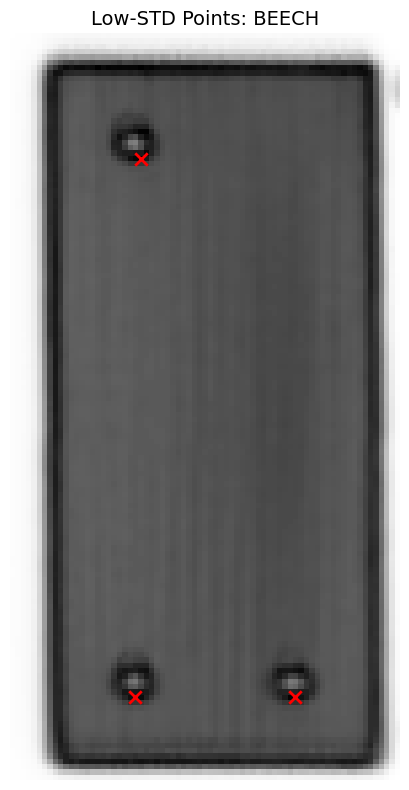


[RED CEDAR] Selected Low-STD Pixel Coordinates:
1. Pixel at (row=123, col=55) with STD = 0.3288
2. Pixel at (row=18, col=21) with STD = 0.3523
3. Pixel at (row=123, col=24) with STD = 0.3559


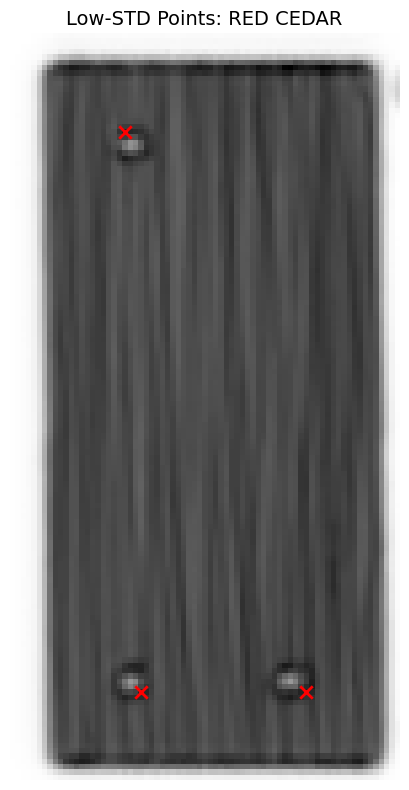


[DOUGLAS FIR] Selected Low-STD Pixel Coordinates:
1. Pixel at (row=124, col=23) with STD = 0.2793
2. Pixel at (row=23, col=23) with STD = 0.2802
3. Pixel at (row=124, col=53) with STD = 0.2930


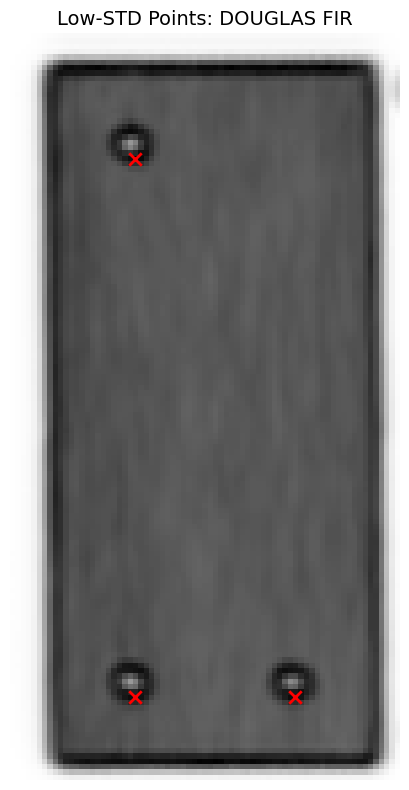


[POPLAR] Selected Low-STD Pixel Coordinates:
1. Pixel at (row=22, col=24) with STD = 0.3138
2. Pixel at (row=123, col=54) with STD = 0.3304
3. Pixel at (row=123, col=24) with STD = 0.3529


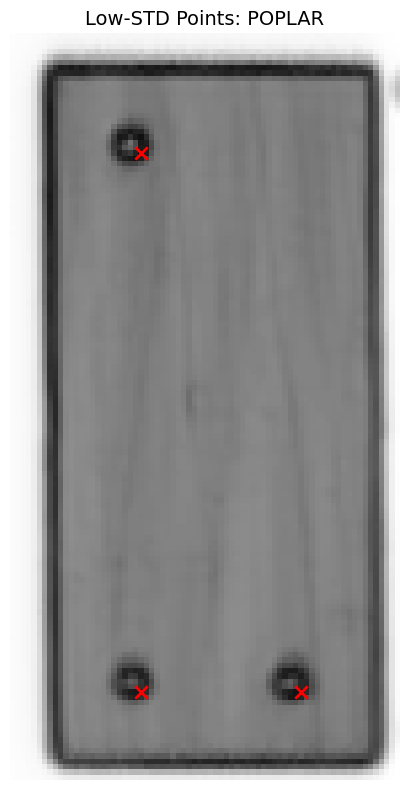


[OAK] Selected Low-STD Pixel Coordinates:
1. Pixel at (row=18, col=21) with STD = 0.3876
2. Pixel at (row=118, col=22) with STD = 0.3926
3. Pixel at (row=119, col=51) with STD = 0.3972


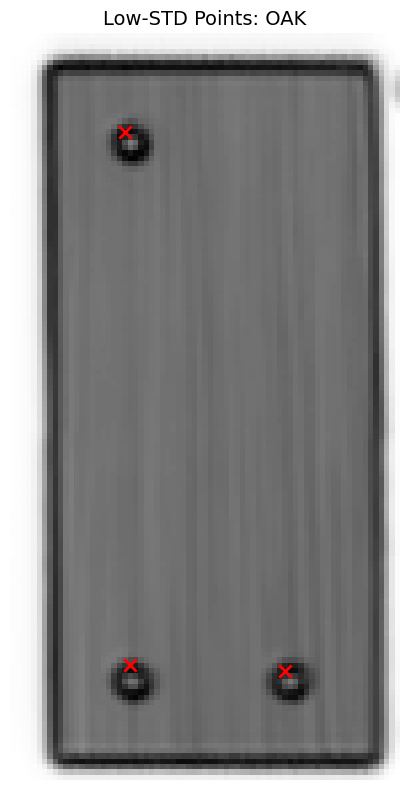

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.spatial.distance import cdist

# Config
border = 10
num_points = 3
min_dist = 20

# Load metadata
df = pd.read_csv("/content/drive/MyDrive/wood data/wood/Dimensions/Diverse_dimensions.csv")
df['Species'] = df['Species'].str.strip().str.lower()

H, W = data.shape[1:3]
valid_mask = np.zeros((H, W), dtype=bool)
valid_mask[border:H-border, border:W-border] = True

unique_species = df['Species'].unique()

for species_name in unique_species:
    sample_indices = df[df["Species"] == species_name].index.tolist()

    # Temporal std dev over time
    species_thz = data[sample_indices]  # [N, H, W, F]
    temporal_std = np.std(species_thz, axis=(0, -1))  # [H, W]

    # Mask borders
    std_masked = np.where(valid_mask, temporal_std, np.inf)

    # Flatten and sort
    flat_indices = np.argsort(std_masked.ravel())
    # Top 5 high-variance pixels
    coords = np.unravel_index(np.argsort(std_map.ravel())[::-1][:5], std_map.shape)


    # Select spatially separated low-STD pixels
    selected = []
    for (r, c) in coords:
        if len(selected) == 0:
            selected.append((r, c))
        else:
            dist = cdist([(r, c)], selected)
            if np.min(dist) >= min_dist:
                selected.append((r, c))
        if len(selected) == num_points:
            break

    # === Print coordinates and STD values
    print(f"\n[{species_name.upper()}] Selected Low-STD Pixel Coordinates:")
    for idx, (r, c) in enumerate(selected, 1):
        print(f"{idx}. Pixel at (row={r}, col={c}) with STD = {temporal_std[r, c]:.4f}")

    # === Plot
    energy_map = np.sum(np.abs(species_thz), axis=(0, 3)) / len(sample_indices)

    plt.figure(figsize=(6, 8))
    plt.imshow(energy_map, cmap='gray')

    for (r, c) in selected:
        plt.scatter(c, r, c='red', s=80, marker='x', linewidths=2)

    plt.title(f"Low-STD Points: {species_name.upper()}", fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()


Best Parameters: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200}
R^2 Score: 0.9415331068505252
MAE: 35.41299753870723


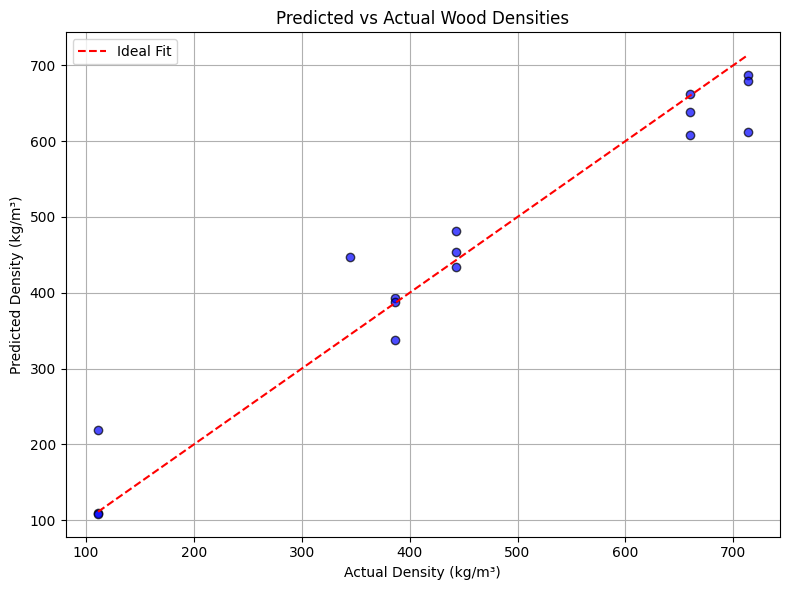

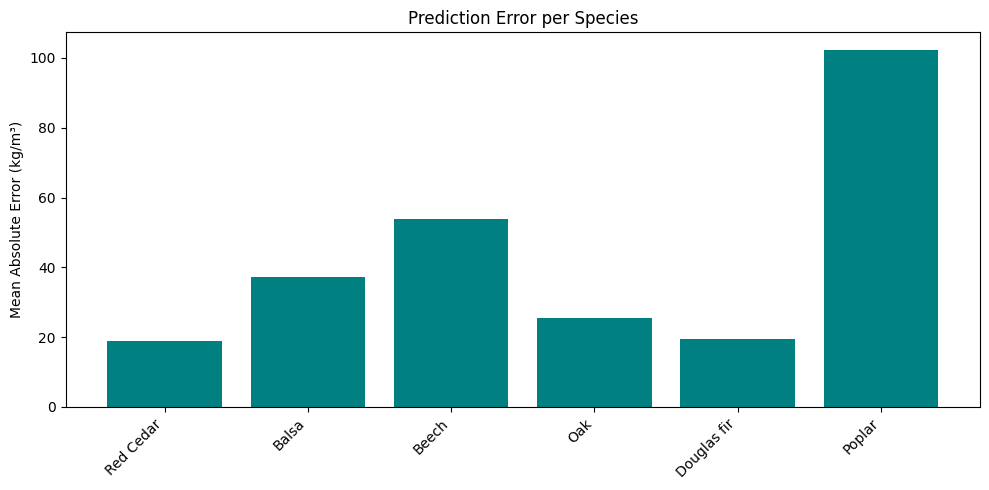

In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import StandardScaler
from collections import defaultdict



df["Species"] = df["Species"].str.strip().str.lower()
density_col = [col for col in df.columns if 'density' in col.lower()][0]
species_density = dict(zip(df["Species"], df[density_col]))

sample_to_species = {"ABa": "Balsa", "BBa": "Balsa", "CBa": "Balsa", "DBa": "Balsa",
    "EBa": "Balsa", "FBa": "Balsa", "GBa": "Balsa", "HBa": "Balsa", "IBa": "Balsa",
    "JBa": "Balsa", "KBa": "Balsa", "LBa": "Balsa",
    "ABe": "Beech", "BBe": "Beech", "CBe": "Beech", "DBe": "Beech", "EBe": "Beech",
    "FBe": "Beech", "GBe": "Beech", "HBe": "Beech", "IBe": "Beech", "JBe": "Beech",
    "KBe": "Beech", "LBe": "Beech",
    "ACe": "Red Cedar", "BCe": "Red Cedar", "CCe": "Red Cedar", "DCe": "Red Cedar",
    "ECe": "Red Cedar", "FCe": "Red Cedar", "GCe": "Red Cedar", "HCe": "Red Cedar",
    "ICe": "Red Cedar", "JCe": "Red Cedar", "KCe": "Red Cedar", "LCe": "Red Cedar",
    "ADR": "Douglas fir", "BDR": "Douglas fir", "EDR": "Douglas fir", "FDR": "Douglas fir",
    "GDR": "Douglas fir", "HDR": "Douglas fir", "IDR": "Douglas fir", "JDR": "Douglas fir",
    "KDR": "Douglas fir", "LDR": "Douglas fir", "ADT": "Douglas fir", "BDT": "Douglas fir",
    "EDT": "Douglas fir", "FDT": "Douglas fir", "GDT": "Douglas fir", "HDT": "Douglas fir",
    "IDT": "Douglas fir", "JDT": "Douglas fir", "KDT": "Douglas fir", "LDT": "Douglas fir",
    "APo": "Poplar", "BPo": "Poplar", "EPo": "Poplar", "FPo": "Poplar", "GPo": "Poplar",
    "HPo": "Poplar", "IPo": "Poplar", "JPo": "Poplar", "KPo": "Poplar", "LPo": "Poplar",
    "AOa": "Oak", "BOa": "Oak", "COa": "Oak", "DOa": "Oak", "EOa": "Oak", "FOa": "Oak",
    "GOa": "Oak", "HOa": "Oak", "IOa": "Oak", "JOa": "Oak", "KOa": "Oak", "LOa": "Oak"}

sample_ids_ordered = list(sample_to_species.keys())
species_list = [sample_to_species[sid] for sid in sample_ids_ordered]


if len(species_list) != data_complex.shape[0]:
    raise ValueError(f"Number of species in species_list ({len(species_list)}) does not match the number of samples in data_complex ({data_complex.shape[0]}).")


def extract_features(signal):

    mag = np.abs(signal)
    phase = np.angle(signal)

    # Flatten
    mag_flat = mag.flatten()
    phase_flat = phase.flatten()

    # FFT features - apply FFT along the time dimension (axis=0)
    fft_mag = np.abs(np.fft.fft(signal, axis=0))
    # Average over frequency dimension (axis=1) - NOT APPLICABLE HERE as signal is [T]


    # Time derivatives - apply diff along the time dimension (axis=0)
    grad = np.abs(np.diff(mag, axis=0)).mean()

    features = [
        mag.mean(), mag.std(), np.max(mag), np.min(mag),
        np.median(mag), skew(mag_flat), kurtosis(mag_flat),
        phase.mean(), phase.std(), np.median(phase),
        np.mean(fft_mag), np.std(fft_mag), np.max(fft_mag), # Use fft_mag directly as it's [T]
        grad
    ]
    return features

# --- Build Dataset ---
X, y, species_labels = [], [], []
for i, species in enumerate(species_list):
    clean_name = species.strip().lower()
    density = species_density.get(clean_name)
    if density is None:
        continue
    sample = data_complex[i]  # shape: [T, H, W]
    T, H, W = sample.shape # Unpack the 3 dimensions of the sample array

    row_c, col_c = H // 2, W // 2
    patch = [(r, c) for r in range(row_c - 1, row_c + 2) for c in range(col_c - 1, col_c + 2)]

    patch_feats = []
    for r, c in patch:
        signal = sample[:, r, c]
        patch_feats.append(extract_features(signal))
    X.append(np.mean(patch_feats, axis=0))
    y.append(density)
    species_labels.append(species)

X, y = np.array(X), np.array(y)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


X_train, X_test, y_train, y_test, species_train, species_test = train_test_split(X_scaled, y, species_labels, test_size=0.2, random_state=42)


param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2]
}

grid = GridSearchCV(XGBRegressor(objective='reg:squarederror'), param_grid, cv=3)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)


print("Best Parameters:", grid.best_params_)
print("R^2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))


plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, c='blue', edgecolors='k', alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--', label='Ideal Fit')
plt.xlabel('Actual Density (kg/m³)')
plt.ylabel('Predicted Density (kg/m³)')
plt.title('Predicted vs Actual Wood Densities')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


errors_by_species = defaultdict(list)
for true, pred, name in zip(y_test, y_pred, species_test):
    errors_by_species[name].append(abs(true - pred))

species_names = list(errors_by_species.keys())
mean_errors = [np.mean(errors_by_species[s]) for s in species_names]

plt.figure(figsize=(10, 5))
plt.bar(species_names, mean_errors, color='teal')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Mean Absolute Error (kg/m³)')
plt.title('Prediction Error per Species')
plt.tight_layout()
plt.show()

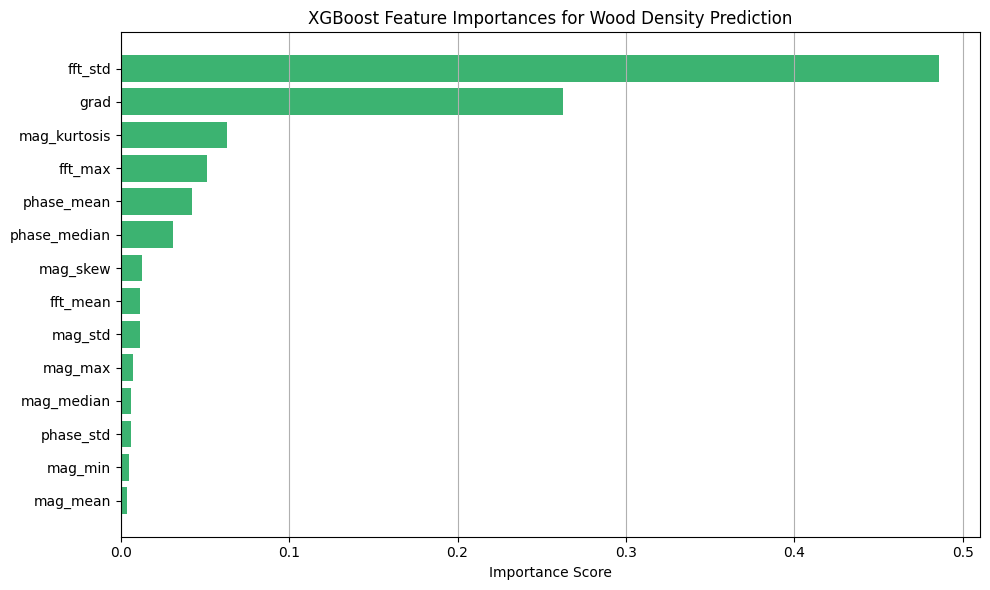

In [ ]:
  # --- XGBoost Feature Importances ---
feature_names = [
    "mag_mean", "mag_std", "mag_max", "mag_min", "mag_median",
    "mag_skew", "mag_kurtosis",
    "phase_mean", "phase_std", "phase_median",
    "fft_mean", "fft_std", "fft_max",
    "grad"
]

importances = best_model.feature_importances_
sorted_idx = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.barh(np.array(feature_names)[sorted_idx], importances[sorted_idx], color='mediumseagreen')
plt.xlabel("Importance Score")
plt.title("XGBoost Feature Importances for Wood Density Prediction")
plt.grid(axis='x')
plt.tight_layout()
plt.show()


In [ ]:
# --- Display Actual vs Predicted Densities ---
results_df = pd.DataFrame({
    "Species": species_test,
    "Actual Density": y_test,
    "Predicted Density": y_pred
})

# Sort by actual density (optional)
results_df = results_df.sort_values(by="Actual Density").reset_index(drop=True)

# Display top 10 rows
print(results_df.head(10))  # or use display(results_df.head(10)) in Jupyter

       Species  Actual Density  Predicted Density
0        Balsa      111.327501         218.708466
1        Balsa      111.327501         109.870834
2        Balsa      111.327501         108.604332
3       Poplar      344.307549         446.532043
4    Red Cedar      386.441537         388.068268
5    Red Cedar      386.441537         337.891388
6    Red Cedar      386.441537         393.228851
7  Douglas fir      442.641229         481.114136
8  Douglas fir      442.641229         434.030151
9  Douglas fir      442.641229         453.717590


In [ ]:
# --- Create a DataFrame with actual vs predicted densities ---
comparison_df = pd.DataFrame({
    "Species": species_test,
    "Actual_Density": y_test,
    "Predicted_Density": y_pred,
    "Absolute_Error": np.abs(y_test - y_pred)
})

# Sort by Species or Error if needed
comparison_df = comparison_df.sort_values(by=["Species"])
pd.set_option('display.max_rows', None)

# Display as table
print(comparison_df.to_string(index=False))


    Species  Actual_Density  Predicted_Density  Absolute_Error
      Balsa        4.721419         373.133789      368.412370
      Balsa        4.721419         343.682190      338.960771
      Balsa        4.721419         600.620117      595.898698
      Balsa        4.721419         111.266258      106.544840
      Beech        6.571075         546.156433      539.585358
      Beech        6.571075         559.419067      552.847992
Douglas fir        6.095016         538.981750      532.886734
        Oak        6.494148         678.966309      672.472160
        Oak        6.494148         566.973816      560.479668
        Oak        6.494148         679.646240      673.152092
     Poplar        5.844435         463.437378      457.592942
     Poplar        5.844435         460.120911      454.276475
  Red Cedar        5.959565         575.210999      569.251434
  Red Cedar        5.959565         396.597900      390.638335


In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.3 MB/s eta 0:00:00


In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 7.8 MB/s eta 0:00:00


R^2 Score: 0.9991563479314388
MAE: 4.823253969223257


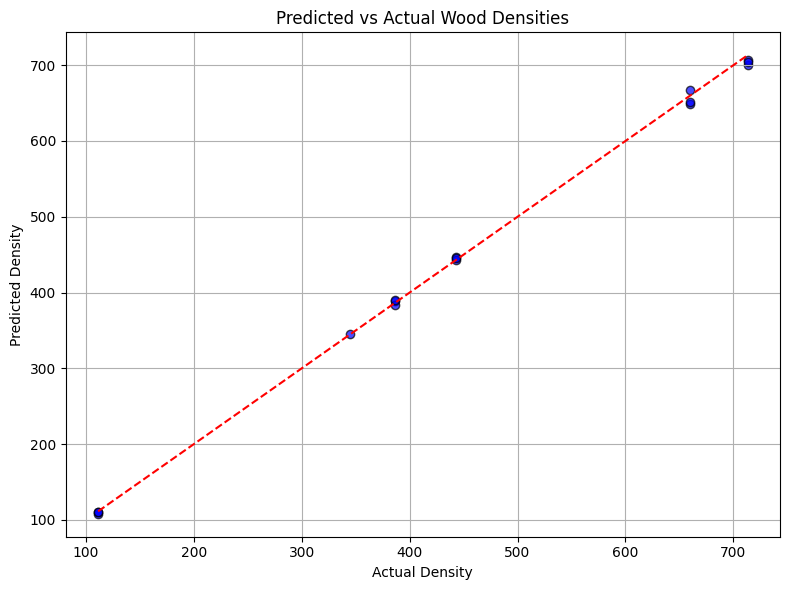

        Species  Actual Density  Predicted Density
1         Balsa      111.327501         108.070551
4         Balsa      111.327501         110.683270
7         Balsa      111.327501         109.995285
3         Beech      713.137115         700.331946
11        Beech      713.137115         707.240671
14        Beech      713.137115         704.758834
8   Douglas fir      442.641229         447.405922
13  Douglas fir      442.641229         443.501143
15  Douglas fir      442.641229         445.275960
5           Oak      660.260719         648.710331
9           Oak      660.260719         666.724806
12          Oak      660.260719         651.386545
10       Poplar      344.307549         344.721548
0     Red Cedar      386.441537         389.332304
2     Red Cedar      386.441537         384.167170
6     Red Cedar      386.441537         390.573194
Group-wise R^2 scores: [-3.50907781e+28 -4.66305757e+00  0.00000000e+00  0.00000000e+00
 -2.78995170e+30]
Mean R^2: -5.65008496588324

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_regression
from scipy.stats import skew, kurtosis, entropy
from scipy.signal import stft
from collections import defaultdict
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge


npy_path = '/content/drive/MyDrive/wood data/wood/Thz/Copy of Diverse_THz.npy'
data_complex = np.load(npy_path, mmap_mode='r')


df["Species"] = df["Species"].str.strip().str.lower()
density_col = [col for col in df.columns if 'density' in col.lower()][0]
species_density = dict(zip(df["Species"], df[density_col]))


sample_to_species = {"ABa": "Balsa", "BBa": "Balsa", "CBa": "Balsa", "DBa": "Balsa",
    "EBa": "Balsa", "FBa": "Balsa", "GBa": "Balsa", "HBa": "Balsa", "IBa": "Balsa",
    "JBa": "Balsa", "KBa": "Balsa", "LBa": "Balsa",
    "ABe": "Beech", "BBe": "Beech", "CBe": "Beech", "DBe": "Beech", "EBe": "Beech",
    "FBe": "Beech", "GBe": "Beech", "HBe": "Beech", "IBe": "Beech", "JBe": "Beech",
    "KBe": "Beech", "LBe": "Beech",
    "ACe": "Red Cedar", "BCe": "Red Cedar", "CCe": "Red Cedar", "DCe": "Red Cedar",
    "ECe": "Red Cedar", "FCe": "Red Cedar", "GCe": "Red Cedar", "HCe": "Red Cedar",
    "ICe": "Red Cedar", "JCe": "Red Cedar", "KCe": "Red Cedar", "LCe": "Red Cedar",
    "ADR": "Douglas fir", "BDR": "Douglas fir", "EDR": "Douglas fir", "FDR": "Douglas fir",
    "GDR": "Douglas fir", "HDR": "Douglas fir", "IDR": "Douglas fir", "JDR": "Douglas fir",
    "KDR": "Douglas fir", "LDR": "Douglas fir", "ADT": "Douglas fir", "BDT": "Douglas fir",
    "EDT": "Douglas fir", "FDT": "Douglas fir", "GDT": "Douglas fir", "HDT": "Douglas fir",
    "IDT": "Douglas fir", "JDT": "Douglas fir", "KDT": "Douglas fir", "LDT": "Douglas fir",
    "APo": "Poplar", "BPo": "Poplar", "EPo": "Poplar", "FPo": "Poplar", "GPo": "Poplar",
    "HPo": "Poplar", "IPo": "Poplar", "JPo": "Poplar", "KPo": "Poplar", "LPo": "Poplar",
    "AOa": "Oak", "BOa": "Oak", "COa": "Oak", "DOa": "Oak", "EOa": "Oak", "FOa": "Oak",
    "GOa": "Oak", "HOa": "Oak", "IOa": "Oak", "JOa": "Oak", "KOa": "Oak", "LOa": "Oak"}

sample_ids_ordered = list(sample_to_species.keys())
species_list = [sample_to_species[sid] for sid in sample_ids_ordered]

if len(species_list) != data_complex.shape[0]:
    raise ValueError(f"Number of species in species_list ({len(species_list)}) does not match the number of samples in data_complex ({data_complex.shape[0]}).")

def extract_features(signal):
    mag = np.abs(signal)
    phase = np.angle(signal)
    fft_mag = np.abs(np.fft.fft(signal))
    grad = np.abs(np.diff(mag)).mean()

    f, t, Zxx = stft(signal, nperseg=16)
    stft_mag = np.abs(Zxx)

    def signal_entropy(x):
        p = np.abs(x)**2
        p /= p.sum() + 1e-10
        return -np.sum(p * np.log2(p + 1e-10))

    zcr = ((np.diff(np.sign(mag)) != 0).sum()) / len(mag)

    features = [
        mag.mean(), mag.std(), np.max(mag), np.min(mag), np.median(mag),
        skew(mag), kurtosis(mag),
        phase.mean(), phase.std(), np.median(phase),
        np.mean(fft_mag), np.std(fft_mag), np.max(fft_mag),
        grad, signal_entropy(fft_mag), np.argmax(fft_mag), zcr,
        np.mean(stft_mag), np.std(stft_mag), np.max(stft_mag),
        np.mean(np.sum(stft_mag, axis=0))
    ]
    return features


X, y, species_labels = [], [], []
for i, species in enumerate(species_list):
    clean_name = species.strip().lower()
    density = species_density.get(clean_name)
    if density is None:
        continue

    sample = data_complex[i]
    T, H, W = sample.shape
    std_map = np.std(np.abs(sample), axis=0)
    coords = np.unravel_index(np.argsort(-std_map.ravel())[:5], std_map.shape)  # top 5 high-variance pixels
    patch_feats = [extract_features(sample[:, r, c]) for r, c in zip(*coords)]

    X.append(np.mean(patch_feats, axis=0))
    y.append(density)
    species_labels.append(species)

X, y = np.array(X), np.array(y)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

species_array = np.array(species_labels).reshape(-1, 1)
encoder = OneHotEncoder(sparse_output=False)
species_encoded = encoder.fit_transform(species_array)

X_final = np.concatenate([X_scaled, species_encoded], axis=1)

y_log = np.log1p(y)

X_train, X_test, y_train, y_test, species_train, species_test = train_test_split(
    X_final, y_log, species_labels, test_size=0.2, random_state=42)


stack_model = StackingRegressor(
    estimators=[
        ('cat', CatBoostRegressor(verbose=0)),
        ('xgb', XGBRegressor(objective='reg:squarederror')),
        ('rf', RandomForestRegressor())
    ],
    final_estimator=Ridge()
)

stack_model.fit(X_train, y_train)
y_pred_log = stack_model.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_true = np.expm1(y_test)

print("R^2 Score:", r2_score(y_true, y_pred))
print("MAE:", mean_absolute_error(y_true, y_pred))

plt.figure(figsize=(8, 6))
plt.scatter(y_true, y_pred, c='blue', edgecolors='k', alpha=0.7)
plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--')
plt.xlabel('Actual Density')
plt.ylabel('Predicted Density')
plt.title('Predicted vs Actual Wood Densities')
plt.grid(True)
plt.tight_layout()
plt.show()

pd.set_option('display.max_rows', None)
results_df = pd.DataFrame({
    'Species': species_test,
    'Actual Density': y_true,
    'Predicted Density': y_pred
})
print(results_df.sort_values(by='Species'))


gkf = GroupKFold(n_splits=5)
scores = cross_val_score(stack_model, X_final, y_log, groups=species_labels, cv=gkf, scoring='r2')
print("Group-wise R^2 scores:", scores)
print("Mean R^2:", scores.mean())

In [ ]:

species_counts = df['Species'].value_counts()
print("Number of samples per species:\n", species_counts)


species_list_counts = pd.Series(species_labels).value_counts()
print("\nNumber of samples per species in the processed data:\n", species_list_counts)

Number of samples per species:
 Species
douglas fir    20
balsa          12
beech          12
red cedar      12
oak            12
poplar         10
Name: count, dtype: int64

Number of samples per species in the processed data:
 balsa          1
beech          1
red cedar      1
douglas fir    1
poplar         1
oak            1
Name: count, dtype: int64


/tmp/ipython-input-5-3322555704.py:56: UserWarning: Input data is complex, switching to return_onesided=False
  f, t, Zxx = stft(signal, nperseg=16)


R^2: 0.9992466283518021
MAE: 4.650955359285617


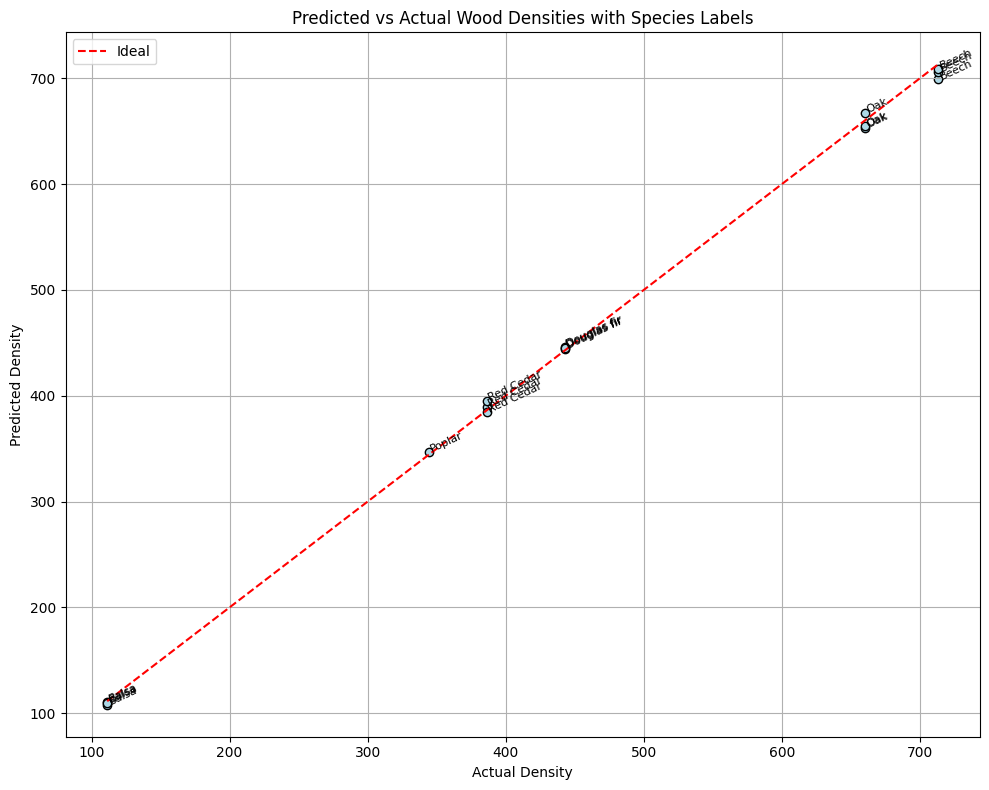

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.stats import skew, kurtosis
from scipy.signal import stft
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from collections import defaultdict


npy_path = '/content/drive/MyDrive/wood data/wood/Thz/Copy of Diverse_THz.npy'
data_complex = np.load(npy_path, mmap_mode='r')


df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Diverse_dimensions.csv')
df["Species"] = df["Species"].str.strip().str.lower()
density_col = [col for col in df.columns if 'density' in col.lower()][0]
species_density = dict(zip(df["Species"], df[density_col]))


sample_to_species = {"ABa": "Balsa", "BBa": "Balsa", "CBa": "Balsa", "DBa": "Balsa",
    "EBa": "Balsa", "FBa": "Balsa", "GBa": "Balsa", "HBa": "Balsa", "IBa": "Balsa",
    "JBa": "Balsa", "KBa": "Balsa", "LBa": "Balsa",
    "ABe": "Beech", "BBe": "Beech", "CBe": "Beech", "DBe": "Beech", "EBe": "Beech",
    "FBe": "Beech", "GBe": "Beech", "HBe": "Beech", "IBe": "Beech", "JBe": "Beech",
    "KBe": "Beech", "LBe": "Beech",
    "ACe": "Red Cedar", "BCe": "Red Cedar", "CCe": "Red Cedar", "DCe": "Red Cedar",
    "ECe": "Red Cedar", "FCe": "Red Cedar", "GCe": "Red Cedar", "HCe": "Red Cedar",
    "ICe": "Red Cedar", "JCe": "Red Cedar", "KCe": "Red Cedar", "LCe": "Red Cedar",
    "ADR": "Douglas fir", "BDR": "Douglas fir", "EDR": "Douglas fir", "FDR": "Douglas fir",
    "GDR": "Douglas fir", "HDR": "Douglas fir", "IDR": "Douglas fir", "JDR": "Douglas fir",
    "KDR": "Douglas fir", "LDR": "Douglas fir", "ADT": "Douglas fir", "BDT": "Douglas fir",
    "EDT": "Douglas fir", "FDT": "Douglas fir", "GDT": "Douglas fir", "HDT": "Douglas fir",
    "IDT": "Douglas fir", "JDT": "Douglas fir", "KDT": "Douglas fir", "LDT": "Douglas fir",
    "APo": "Poplar", "BPo": "Poplar", "EPo": "Poplar", "FPo": "Poplar", "GPo": "Poplar",
    "HPo": "Poplar", "IPo": "Poplar", "JPo": "Poplar", "KPo": "Poplar", "LPo": "Poplar",
    "AOa": "Oak", "BOa": "Oak", "COa": "Oak", "DOa": "Oak", "EOa": "Oak", "FOa": "Oak",
    "GOa": "Oak", "HOa": "Oak", "IOa": "Oak", "JOa": "Oak", "KOa": "Oak", "LOa": "Oak"}

sample_ids_ordered = list(sample_to_species.keys())
species_list = [sample_to_species[sid] for sid in sample_ids_ordered]

if len(species_list) != data_complex.shape[0]:
    raise ValueError("Species list and data mismatch.")

def extract_features(signal):
    mag = np.abs(signal)
    phase = np.angle(signal)
    fft_mag = np.abs(np.fft.fft(signal))
    grad = np.abs(np.diff(mag)).mean()
    f, t, Zxx = stft(signal, nperseg=16)
    stft_mag = np.abs(Zxx)
    def signal_entropy(x):
        p = np.abs(x)**2
        p /= p.sum() + 1e-10
        return -np.sum(p * np.log2(p + 1e-10))
    zcr = ((np.diff(np.sign(mag)) != 0).sum()) / len(mag)
    return [
        mag.mean(), mag.std(), np.max(mag), np.min(mag), np.median(mag),
        skew(mag), kurtosis(mag),
        phase.mean(), phase.std(), np.median(phase),
        np.mean(fft_mag), np.std(fft_mag), np.max(fft_mag),
        grad, signal_entropy(fft_mag), np.argmax(fft_mag), zcr,
        np.mean(stft_mag), np.std(stft_mag), np.max(stft_mag),
        np.mean(np.sum(stft_mag, axis=0))
    ]


X, y, species_labels = [], [], []
for i, species in enumerate(species_list):
    dens = species_density.get(species.lower())
    if dens is None:
        continue
    sample = data_complex[i]
    std_map = np.std(np.abs(sample), axis=0)
    coords = np.unravel_index(np.argsort(-std_map.ravel())[:5], std_map.shape)
    feats = [extract_features(sample[:, r, c]) for r, c in zip(*coords)]
    X.append(np.mean(feats, axis=0))
    y.append(dens)
    species_labels.append(species)

X = StandardScaler().fit_transform(X)
species_array = np.array(species_labels).reshape(-1, 1)
species_encoded = OneHotEncoder(sparse_output=False).fit_transform(species_array)
X_final = np.concatenate([X, species_encoded], axis=1)
y_log = np.log1p(y)


from sklearn.utils import shuffle


species_labels_np = np.array(species_labels)

X_train, X_test, y_train, y_test, species_train, species_test = train_test_split(
    X_final, y_log, species_labels_np, test_size=0.2, random_state=42, shuffle=True)


stack_model = StackingRegressor(
    estimators=[
        ('cat', CatBoostRegressor(verbose=0)),
        ('xgb', XGBRegressor(objective='reg:squarederror')),
        ('rf', RandomForestRegressor())
    ],
    final_estimator=Ridge()
)


stack_model.fit(X_train, y_train)
y_pred_log = stack_model.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_true = np.expm1(y_test)


print("R^2:", r2_score(y_true, y_pred))
print("MAE:", mean_absolute_error(y_true, y_pred))


plt.figure(figsize=(10, 8))
plt.scatter(y_true, y_pred, c='lightblue', edgecolors='k')
for i, txt in enumerate(species_test):
    plt.annotate(txt, (y_true[i], y_pred[i]), fontsize=8, rotation=25)
plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--', label='Ideal')
plt.xlabel("Actual Density")
plt.ylabel("Predicted Density")
plt.title("Predicted vs Actual Wood Densities with Species Labels")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

print(f"\n{'Species':<15}{'Actual Density':>15}{'Predicted Density':>20}")
for species, actual, pred in zip(species_test, y_true, y_pred):
    print(f"{species:<15}{actual:15.2f}{pred:20.2f}")



Species         Actual Density   Predicted Density
Red Cedar               386.44              389.37
Balsa                   111.33              108.09
Red Cedar               386.44              383.84
Beech                   713.14              694.95
Balsa                   111.33              110.70
Oak                     660.26              651.37
Red Cedar               386.44              394.69
Balsa                   111.33              110.01
Douglas fir             442.64              447.02
Oak                     660.26              664.07
Poplar                  344.31              344.93
Beech                   713.14              705.44
Oak                     660.26              653.20
Douglas fir             442.64              442.25
Beech                   713.14              709.87
Douglas fir             442.64              444.03


In [ ]:
import time


start_train = time.time()
stack_model.fit(X_train, y_train)
end_train = time.time()
train_time = end_train - start_train


start_test = time.time()
y_pred_log = stack_model.predict(X_test)
end_test = time.time()
test_time = end_test - start_test


y_pred = np.expm1(y_pred_log)
y_true = np.expm1(y_test)


print(f"Training time: {train_time:.2f} seconds")
print(f"Testing time: {test_time:.2f} seconds")


Training time: 27.18 seconds
Testing time: 0.01 seconds


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error


y_train_pred_log = stack_model.predict(X_train)
y_train_pred = np.expm1(y_train_pred_log)
y_train_true = np.expm1(y_train)


y_test_pred_log = stack_model.predict(X_test)
y_test_pred = np.expm1(y_test_pred_log)
y_test_true = np.expm1(y_test)

print("Train R²:", r2_score(y_train_true, y_train_pred))
print("Train MAE:", mean_absolute_error(y_train_true, y_train_pred))
print("Test R²:", r2_score(y_test_true, y_test_pred))
print("Test MAE:", mean_absolute_error(y_test_true, y_test_pred))


Train R²: 0.9995932350324107
Train MAE: 2.69249392511108
Test R²: 0.9992466283518021
Test MAE: 4.650955359285617


Model performance  evaluation

LOSO Evaluation: 100%|██████████| 78/78 [10:19<00:00,  7.94s/it]



 LOSO with GridSearch:
R² Score: 0.9542
MAE: 21.87 kg/m³


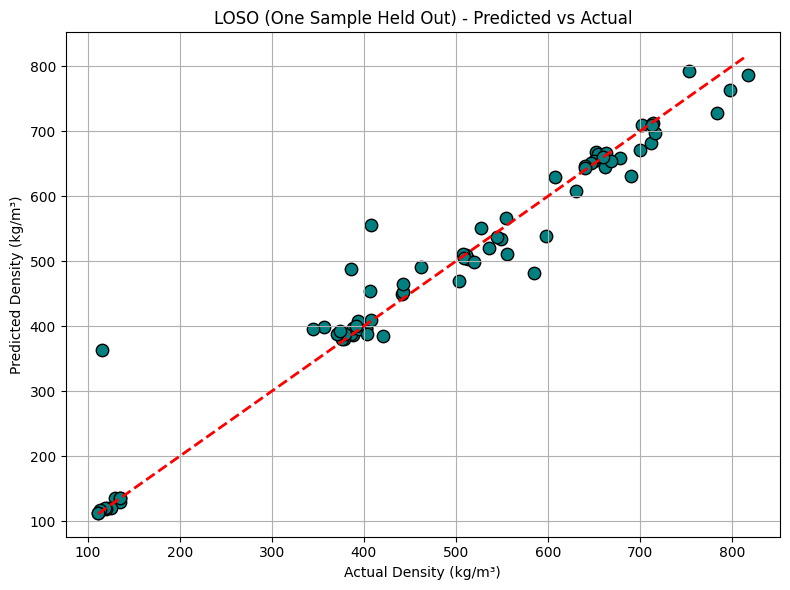

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft2
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error
from tqdm import tqdm

df = pd.read_csv('/content/drive/MyDrive/wood data/wood/Dimensions/Diverse_dimensions.csv')

data_real = np.load('/content/drive/MyDrive/wood data/wood/Thz/Copy of Diverse_THz.npy')

df["Volume_cm3"] = (df["Length (mm)"] * df["Width (mm)"] * df["Thickness (mm)"]) / 1000
MC_9 = 0.09
df["m9"] = df["Mass (g)"] / (1 + MC_9)
df["MC_t"] = MC_9 + ((df["m9"] - df["Mass (g)"]) / df["m9"]) * (1 + MC_9)

samples = []
labels = []

for i in range(data_real.shape[0]):

    image = np.abs(data_real[i]).mean(axis=0)
    H, W = image.shape
    image_flat = image.reshape(-1)

    top_idxs = np.argsort(np.abs(image_flat - image_flat.mean()))[-5:]

    mass = df.loc[i, "Mass (g)"]
    volume = df.loc[i, "Volume_cm3"]
    mc_t = df.loc[i, "MC_t"]
    density = df.loc[i, "Density (kg/m3)"]

    for idx in top_idxs:
        h = idx // W
        w = idx % W
        pixel_val = image[h, w]

        patch_size = 5
        h0 = max(0, h - patch_size // 2)
        h1 = min(H, h + patch_size // 2 + 1)
        w0 = max(0, w - patch_size // 2)
        w1 = min(W, w + patch_size // 2 + 1)
        patch = image[h0:h1, w0:w1]

        if patch.ndim == 1:
            patch = np.expand_dims(patch, axis=0)
        elif patch.ndim == 0:
             patch = np.array([[patch]])

        if patch.size == 0 or 1 in patch.shape:

             fft_mean = 0
             fft_peak = 0
             patch_std = 0
        else:
             spectrum2d = np.abs(fft2(patch))
             fft_mean = spectrum2d.mean()
             fft_peak = spectrum2d.max()
             patch_std = patch.std()


        features = [
            mass, volume, mc_t,
            pixel_val,
            patch_std,
            fft_mean,
            fft_peak
        ]
        samples.append(features)
        labels.append(density)


X = pd.DataFrame(samples, columns=[
    "Mass", "Volume", "MC_t",
    "Pixel_Mean", "Pixel_Std",
    "FFT_Mean", "FFT_Peak"
])
y = np.array(labels)


num_samples = df.shape[0]
preds = []
true_vals = []

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_split": [2, 5]
}

for i in tqdm(range(num_samples), desc="LOSO Evaluation"):

    test_idx = list(range(i * 5, (i + 1) * 5))

    train_idx = list(set(range(len(X))) - set(test_idx))

    X_train = X.iloc[train_idx]
    y_train = y[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y[test_idx]

    grid = GridSearchCV(
        RandomForestRegressor(random_state=42),
        param_grid,
        cv=3,
        scoring='r2',
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    best_model = grid.best_estimator_

    y_pred = best_model.predict(X_test)

    preds.append(np.mean(y_pred))

    true_vals.append(y_test[0])


r2 = r2_score(true_vals, preds)
mae = mean_absolute_error(true_vals, preds)

print("\n LOSO with GridSearch:")
print("R² Score:", round(r2, 4))
print("MAE:", round(mae, 2), "kg/m³")


plt.figure(figsize=(8, 6))
plt.scatter(true_vals, preds, color='teal', edgecolor='k', s=80)
plt.plot([min(true_vals), max(true_vals)], [min(true_vals), max(true_vals)], 'r--', lw=2)
plt.xlabel("Actual Density (kg/m³)")
plt.ylabel("Predicted Density (kg/m³)")
plt.title("LOSO (One Sample Held Out) - Predicted vs Actual")
plt.grid(True)
plt.tight_layout()
plt.show()